# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [3]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [4]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [5]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [6]:
import random

numbers = list(range(10))

print("=== ДО set_seed() ===")
for i in range(2):
    a = random.randint(1, 100)
    b = numbers.copy()
    random.shuffle(b)
    print(a, b)

set_seed()
print("Seed зафіксовано:", SEED)

print("=== ПІСЛЯ set_seed() перед кожним генеруванням ===")
for i in range(2):
    set_seed()
    a = random.randint(1, 100)
    set_seed()
    b = numbers.copy()
    random.shuffle(b)
    print(a, b)

print("=== БЕЗ проміжних set_seed() ===")
for i in range(2):
    a = random.randint(1, 100)
    b = numbers.copy()
    random.shuffle(b)
    print(a, b)

=== ДО set_seed() ===
35 [7, 9, 6, 0, 8, 2, 4, 1, 3, 5]
24 [7, 4, 0, 1, 2, 5, 6, 3, 8, 9]
Seed зафіксовано: 42
=== ПІСЛЯ set_seed() перед кожним генеруванням ===
82 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
82 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
=== БЕЗ проміжних set_seed() ===
76 [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]
92 [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [7]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [8]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [9]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
import numpy as np

zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape, zeros_arr.dtype)
print(sevens_arr, sevens_arr.shape, sevens_arr.dtype)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [10]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)

[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [11]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)
print(identity.ndim, random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]
2 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [12]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)

Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [13]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [14]:
df = pd.DataFrame({
    "name": ["Олена", "Іван", "Марія", "Петро", "Софія", "Андрій", "Катерина", "Дмитро"],
    "score": [78, 85, 92, 67, 90, 74, 88, 95]
})

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"] > 80].sort_values("score", ascending=False)
print(top)


       name  score
7    Дмитро     95
2     Марія     92
4     Софія     90
6  Катерина     88
1      Іван     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [15]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = np.select(
    [df["score"] >= 90, df["score"] >= 75],
    ["A", "B"],
    default="C"
)
print(df)

       name  score grade
0     Олена     78     B
1      Іван     85     B
2     Марія     92     A
3     Петро     67     C
4     Софія     90     A
5    Андрій     74     C
6  Катерина     88     B
7    Дмитро     95     A


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [16]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t, zeros_t.shape, zeros_t.dtype)
print(sevens_t, sevens_t.shape, sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [17]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [18]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list, from_list.shape, from_list.dtype, from_list.ndim)
print(random_t, random_t.shape, random_t.dtype, random_t.ndim)

tensor([[1, 2],
        [3, 4]]) torch.Size([2, 2]) torch.int64 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]]) torch.Size([3, 3]) torch.float32 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [19]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("Автоматичний градієнт:", x.grad.item())
print("Аналітичний градієнт:", 2 * n)
print("Збігаються:", x.grad.item() == 2 * n)

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n


Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0
Збігаються: True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [20]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

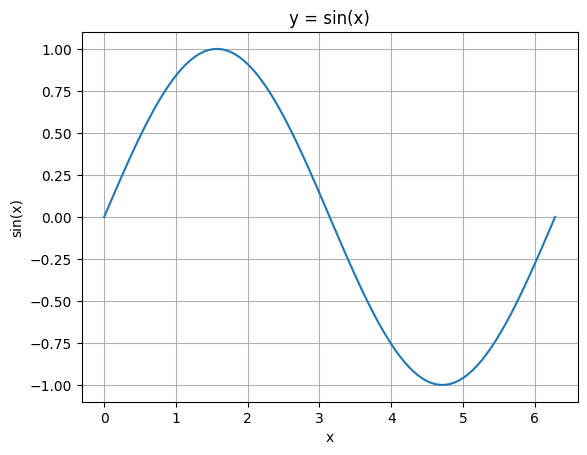

In [21]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
xs = np.linspace(0, 2 * np.pi, 100)

plt.plot(xs, np.sin(xs))
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title("y = sin(x)")
plt.grid(True)
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

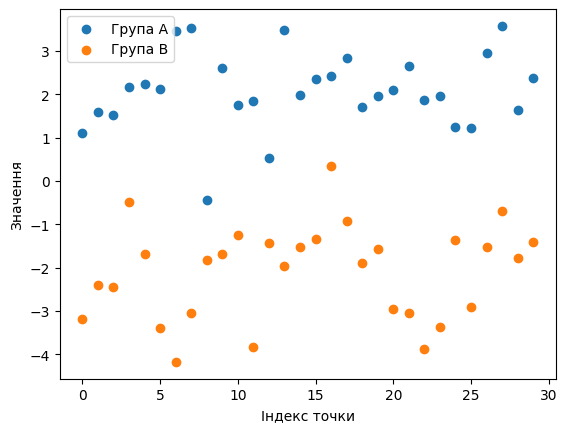

In [22]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

idx = np.arange(30)

plt.scatter(idx, group_a, color="C0", label="Група A")
plt.scatter(idx, group_b, color="C1", label="Група B")
plt.xlabel("Індекс точки")
plt.ylabel("Значення")
plt.legend()
plt.show()

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [23]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

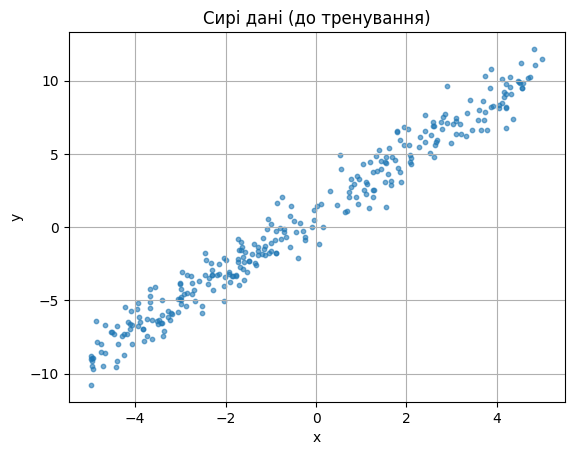

In [24]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1.numpy(), y1.numpy(), s=10, alpha=0.6)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Сирі дані (до тренування)")
plt.grid(True)
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [25]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...

perm = torch.randperm(TASK1_N)
x1_shuf = x1[perm]
y1_shuf = y1[perm]

n_train = int(0.7 * TASK1_N)
n_val = int(0.15 * TASK1_N)

x_train1, y_train1 = x1_shuf[:n_train], y1_shuf[:n_train]
x_val1, y_val1 = x1_shuf[n_train:n_train + n_val], y1_shuf[n_train:n_train + n_val]
x_test1, y_test1 = x1_shuf[n_train + n_val:], y1_shuf[n_train + n_val:]

print(x_train1.shape, x_val1.shape, x_test1.shape)

torch.Size([210, 1]) torch.Size([45, 1]) torch.Size([45, 1])


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [26]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


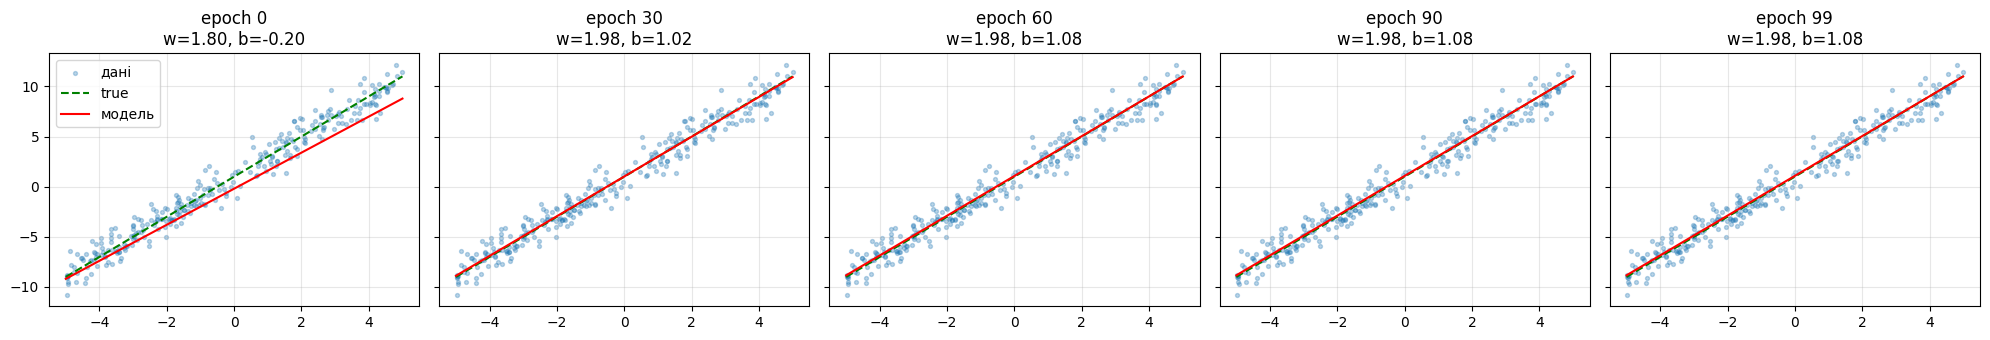

In [27]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

Я обрав залежність між кількістю годин самостійного навчання на тиждень і балом за контрольну (0-100).

Закладена залежність: `y = 5·x + 40 + ε`, де `ε ~ N(0, 6²)`

- **w = 5**: кожна додаткова година навчання дає в середньому +5 балів. Для діапазону 0-10 годин це правдоподібний приріст.
- **b = 40**: базовий бал студента, який майже не готувався. Дещо лишається з лекцій, а частину тесту можна вгадати, тому нуль був би нереалістичним.
- **Діапазон x:** 0-10 годин на тиждень. Максимум близько `40 + 5·10 = 90` балів, тобто значення не виходять за шкалу 0-100.
- **Шум σ = 6:** бал залежить не лише від годин, а й від якості навчання, самопочуття та везіння з білетом.

**Чому нормалізація ознаки.** Тут x (0-10) і y (40-90) мають різний масштаб. У градієнт за `w` входить множник `x`, а в градієнт за `b` ні, тому `w` навчається швидко, а `b` помітно повільніше. Щоб вирівняти це, нормалізую x (z-score, як у Вправі 6) за середнім і std лише з train-вибірки. Після навчання переводжу параметри назад у «справжній» масштаб (години), щоб порівняти з true `w` і `b`.

### Генерація даних

In [28]:
TASK2_TRUE_W = 5.0
TASK2_TRUE_B = 40.0
TASK2_N = 300
TASK2_NOISE_STD = 6.0
TASK2_X_MIN, TASK2_X_MAX = 0.0, 10.0

def generate_study_data(n, w, b, x_min, x_max, noise_std):
    """x -- години навчання на тиждень, y -- бал за контрольну."""
    x = torch.empty(n, 1).uniform_(x_min, x_max)
    noise = noise_std * torch.randn(n, 1)
    y = w * x + b + noise
    return x, y

set_seed()
x2, y2 = generate_study_data(TASK2_N, TASK2_TRUE_W, TASK2_TRUE_B,
                             TASK2_X_MIN, TASK2_X_MAX, TASK2_NOISE_STD)
print(x2.shape, y2.shape)

torch.Size([300, 1]) torch.Size([300, 1])


### Збереження датасету в CSV

Зберігаю згенеровані дані (`x2`, `y2`) у CSV на Google Drive (`dataset.csv`).

Колонки: `study_hours` (години навчання на тиждень) і `score` (бал за контрольну).

In [29]:
def save_dataset_to_csv(x, y, path):
    df_out = pd.DataFrame({
        "study_hours": x.squeeze(1).numpy(),
        "score": y.squeeze(1).numpy()
    })
    df_out.to_csv(path, index=False)
    return df_out

def load_dataset_from_csv(path):
    df_in = pd.read_csv(path)
    x = torch.tensor(df_in["study_hours"].values, dtype=torch.float32).unsqueeze(1)
    y = torch.tensor(df_in["score"].values, dtype=torch.float32).unsqueeze(1)
    return x, y

dataset_path = os.path.join(ARTIFACT_DIR, "dataset.csv")
df_saved = save_dataset_to_csv(x2, y2, dataset_path)
print("Збережено в:", dataset_path)
print(df_saved.head())

x2, y2 = load_dataset_from_csv(dataset_path)
print("Зчитано з CSV:", x2.shape, y2.shape)

Збережено в: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
   study_hours      score
0     8.822693  80.770332
1     9.150040  79.940117
2     3.828638  64.370865
3     9.593057  87.391441
4     3.904482  61.945229
Зчитано з CSV: torch.Size([300, 1]) torch.Size([300, 1])


### Розбиття на train/val/test

Перемішую дані (`torch.randperm`) і ріжу на три частини у пропорції 70/15/15, як у Завданні 1: train для навчання, val для контролю під час тренування, test для фінальної незалежної перевірки.

In [30]:
def split_dataset(x, y, train_frac=0.7, val_frac=0.15):
    n = x.shape[0]
    perm = torch.randperm(n)
    x, y = x[perm], y[perm]
    n_train = int(train_frac * n)
    n_val = int(val_frac * n)
    return (x[:n_train], y[:n_train]), \
           (x[n_train:n_train + n_val], y[n_train:n_train + n_val]), \
           (x[n_train + n_val:], y[n_train + n_val:])

(x_train2, y_train2), (x_val2, y_val2), (x_test2, y_test2) = split_dataset(x2, y2)
print(f"train/val/test: {len(x_train2)}/{len(x_val2)}/{len(x_test2)}")

train/val/test: 210/45/45


### Нормалізація ознаки

Нормалізую x за формулою `(x - mean) / std`, де `mean` і `std` пораховані **лише на train**, щоб не «підглядати» у val/test. Ті самі `mean` і `std` потім застосовуються до val, test і до нових даних в інтерактивній аппці.

In [31]:
def normalize_feature(x_train, x_val, x_test):
    mean, std = x_train.mean(), x_train.std()
    return (x_train - mean) / std, (x_val - mean) / std, (x_test - mean) / std, mean, std

x_train2_n, x_val2_n, x_test2_n, x2_mean, x2_std = normalize_feature(x_train2, x_val2, x_test2)
print(f"mean={x2_mean.item():.3f}, std={x2_std.item():.3f}")

mean=4.779, std=2.968


### Тренування моделі

Той самий цикл навчання, що й у Завданні 1 (SGD + MSELoss), оформлений у перевикористовувану функцію. Тренуємось на нормалізованому x, а після навчання переводжу параметри назад у «справжній» масштаб (години):

`w_real = w_norm / std`, `b_real = b_norm - w_norm · mean / std`

In [32]:
def train_linear_model(x_train, y_train, x_val, y_val, epochs=200, lr=0.05, log_every=40):
    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()

        if epoch % log_every == 0 or epoch == epochs - 1:
            with torch.no_grad():
                val_loss = loss_fn(model(x_val), y_val)
            print(f"epoch {epoch:4d}  train_loss={loss.item():.4f}  val_loss={val_loss.item():.4f}")
    return model

def to_real_scale(model, mean, std):
    w_norm, b_norm = model.weight.item(), model.bias.item()
    w_real = w_norm / std.item()
    b_real = b_norm - w_norm * mean.item() / std.item()
    return w_real, b_real

task2_model = train_linear_model(x_train2_n, y_train2, x_val2_n, y_val2)

w_real, b_real = to_real_scale(task2_model, x2_mean, x2_std)
print(f"\nНавчено: w={w_real:.4f} (true {TASK2_TRUE_W}), b={b_real:.4f} (true {TASK2_TRUE_B})")

epoch    0  train_loss=4410.9141  val_loss=3647.3938
epoch   40  train_loss=32.3063  val_loss=41.2855
epoch   80  train_loss=31.3474  val_loss=39.9852
epoch  120  train_loss=31.3472  val_loss=39.9775
epoch  160  train_loss=31.3472  val_loss=39.9775
epoch  199  train_loss=31.3472  val_loss=39.9775

Навчено: w=5.1307 (true 5.0), b=39.6239 (true 40.0)


### Перевірка на test

Рахую MSE на відкладеній test-вибірці, яку модель не бачила під час навчання. Це фінальна незалежна оцінка. Очікую значення близьке до дисперсії шуму `σ² = 36` (RMSE ≈ 6): суттєво менше було б підозрілим, бо шум принципово непередбачуваний.

In [34]:
def evaluate_model(model, x_test, y_test):
    loss_fn = torch.nn.MSELoss()
    with torch.no_grad():
        test_loss = loss_fn(model(x_test), y_test)
    return test_loss.item()

test_loss2 = evaluate_model(task2_model, x_test2_n, y_test2)
print(f"Test loss (MSE): {test_loss2:.3f}")
print(f"Test RMSE: {test_loss2 ** 0.5:.3f}  (шум: σ = {TASK2_NOISE_STD})")

Test loss (MSE): 42.800
Test RMSE: 6.542  (шум: σ = 6.0)


### Візуалізація результату

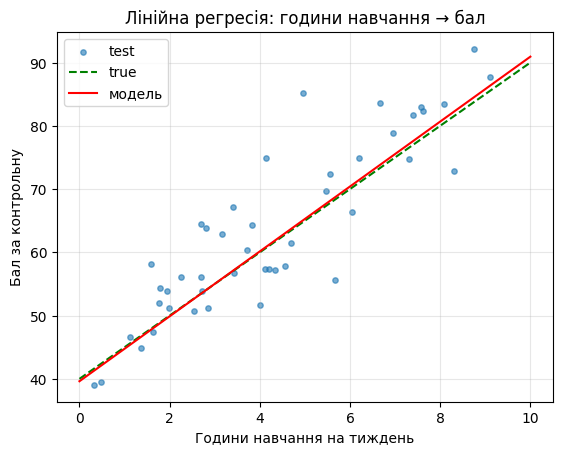

In [35]:
def plot_fit(model, mean, std, x_test, y_test, true_w, true_b, x_min, x_max):
    x_line = torch.linspace(x_min, x_max, 100).unsqueeze(1)
    with torch.no_grad():
        y_line_pred = model((x_line - mean) / std)
    y_line_true = true_w * x_line + true_b

    plt.scatter(x_test.numpy(), y_test.numpy(), s=15, alpha=0.6, label="test")
    plt.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    plt.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    plt.xlabel("Години навчання на тиждень")
    plt.ylabel("Бал за контрольну")
    plt.title("Лінійна регресія: години навчання → бал")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_fit(task2_model, x2_mean, x2_std, x_test2, y_test2,
         TASK2_TRUE_W, TASK2_TRUE_B, TASK2_X_MIN, TASK2_X_MAX)

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [36]:
model_path = os.path.join(ARTIFACT_DIR, "model.pt")
torch.save(task2_model.state_dict(), model_path)
print("Модель збережено в:", model_path)

Модель збережено в: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [37]:
!pip install -q gradio
import gradio as gr

In [38]:
loaded_model = torch.nn.Linear(1, 1)
loaded_model.load_state_dict(torch.load(model_path))
loaded_model.eval()

def predict_score(study_hours):
    x_input = torch.tensor([[study_hours]], dtype=torch.float32)
    x_input_norm = (x_input - x2_mean) / x2_std
    with torch.no_grad():
        prediction = loaded_model(x_input_norm)
    return round(prediction.item(), 2)

demo = gr.Interface(
    fn=predict_score,
    inputs=gr.Number(label="Години навчання на тиждень", value=5),
    outputs=gr.Number(label="Прогнозований бал за контрольну"),
    title="Прогноз балу за годинами навчання",
    description="Лінійна регресія: y = 5·x + 40 (+ шум під час тренування)"
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8e20e3b2a3667610e1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```